In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

from google.colab import files

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
!wget -q https://archive.ics.uci.edu/static/public/352/online+retail.zip -O online_retail.zip

with zipfile.ZipFile("online_retail.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [4]:
df = pd.read_excel("dataset/Online Retail.xlsx")

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice 

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove records without Customer ID
df = df.dropna(subset=['CustomerID'])

# Remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

# Remove negative or zero quantities
df = df[df['Quantity'] > 0]

# Remove invalid prices
df = df[df['UnitPrice'] > 0]

# Convert invoice date
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Calculate total price
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print("Data cleaning completed!")

print("Cleaned Dataset Shape:", df.shape)

display(df.head())

Data cleaning completed!
Cleaned Dataset Shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [7]:
os.makedirs("outputs", exist_ok=True)
os.makedirs("charts", exist_ok=True)
os.makedirs("models", exist_ok=True)

df.to_csv(
    "outputs/cleaned_transaction_dataset.csv",
    index=False
)

print("Cleaned dataset saved!")

Cleaned dataset saved!


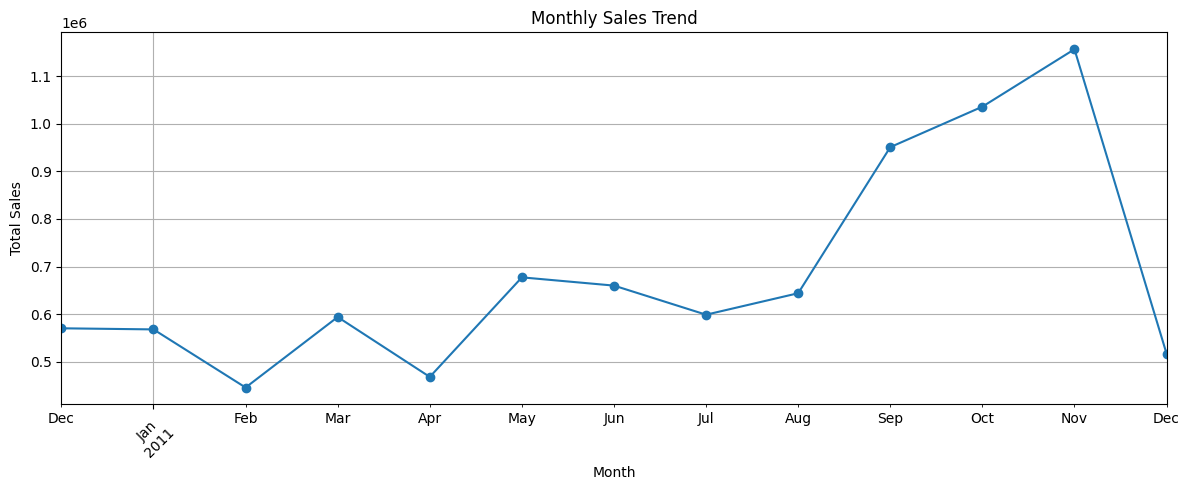

In [8]:
df['Month'] = df['InvoiceDate'].dt.to_period('M')

monthly_sales = df.groupby('Month')['TotalPrice'].sum()

plt.figure(figsize=(12,5))

monthly_sales.plot(kind='line', marker='o')

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.savefig("charts/monthly_sales_trend.png", dpi=300)
plt.show()

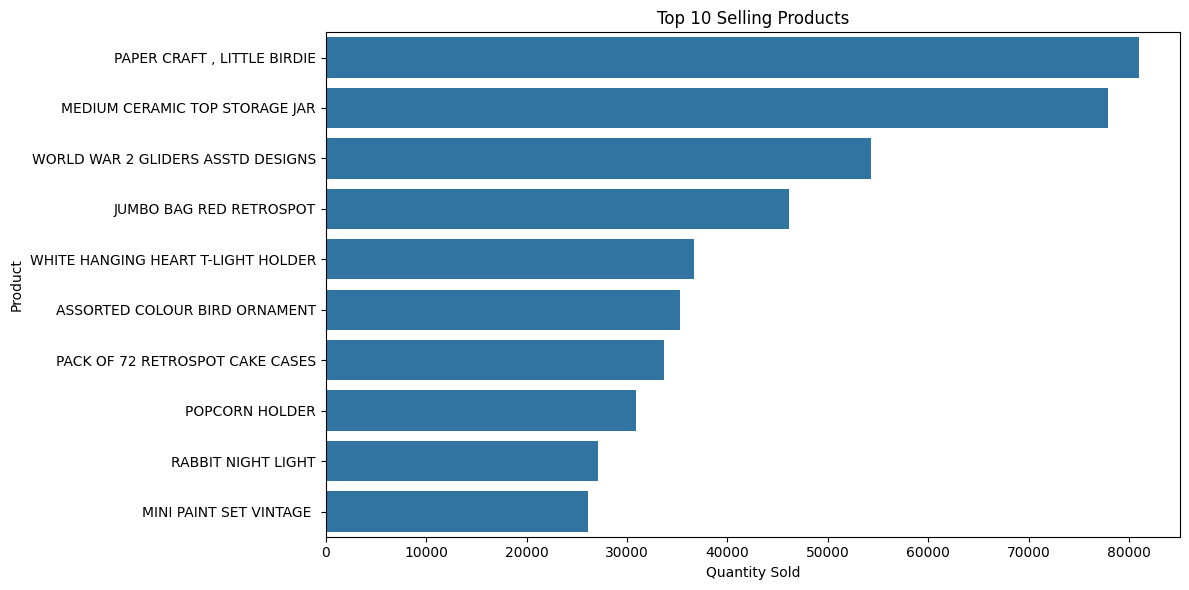

In [9]:
top_products = (
    df.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.savefig("charts/top_10_products.png", dpi=300)
plt.show()

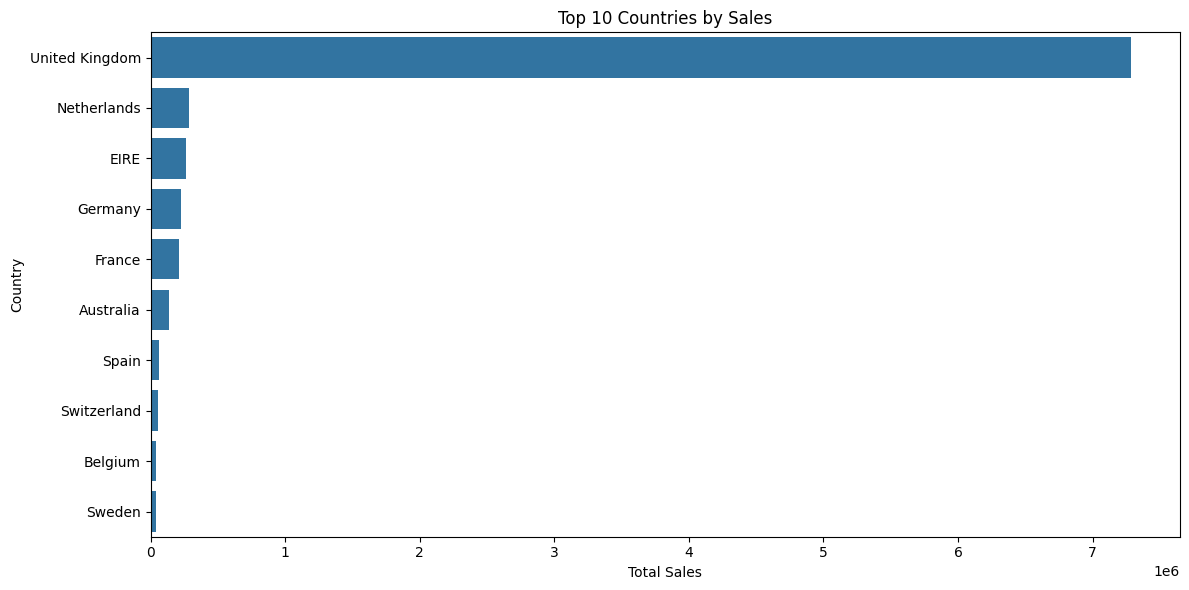

In [10]:
country_sales = (
    df.groupby('Country')['TotalPrice']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=country_sales.values,
    y=country_sales.index
)

plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")

plt.tight_layout()
plt.savefig("charts/country_wise_sales.png", dpi=300)
plt.show()

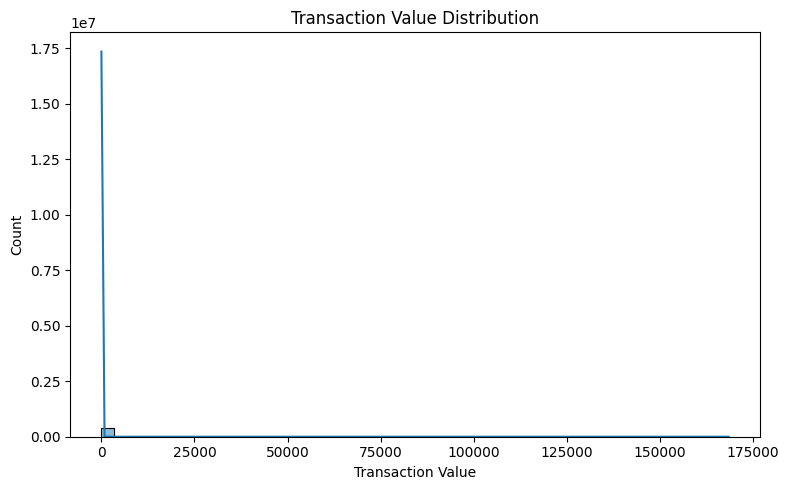

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['TotalPrice'],
    bins=50,
    kde=True
)

plt.title("Transaction Value Distribution")
plt.xlabel("Transaction Value")

plt.tight_layout()
plt.savefig("charts/transaction_value_distribution.png", dpi=300)
plt.show()

In [12]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate',
             lambda x: (reference_date - x.max()).days),

    Frequency=('InvoiceNo', 'nunique'),

    Monetary=('TotalPrice', 'sum')
).reset_index()

print("RFM Analysis Completed!")

display(rfm.head())

RFM Analysis Completed!


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [13]:
customer_features = df.groupby('CustomerID').agg(
    TotalOrders=('InvoiceNo', 'nunique'),

    TotalQuantity=('Quantity', 'sum'),

    TotalSpending=('TotalPrice', 'sum'),

    AverageOrderValue=('TotalPrice', 'sum')
).reset_index()

customer_features['AverageOrderValue'] = (
    customer_features['TotalSpending'] /
    customer_features['TotalOrders']
)

customer_features.to_csv(
    "outputs/customer_level_features.csv",
    index=False
)

rfm.to_csv(
    "outputs/rfm_analysis.csv",
    index=False
)

print("Customer features and RFM data saved!")
display(customer_features.head())

Customer features and RFM data saved!


,CustomerID,TotalOrders,TotalQuantity,TotalSpending,AverageOrderValue
0,12346.0,1,74215,77183.60,77183.600000
1,12347.0,7,2458,4310.00,615.714286
2,12348.0,4,2341,1797.24,449.310000
3,12349.0,1,631,1757.55,1757.550000
4,12350.0,1,197,334.40,334.400000


In [14]:
rfm_columns = ['Recency', 'Frequency', 'Monetary']

# Reduce skewness
rfm_log = np.log1p(rfm[rfm_columns])

# Apply StandardScaler
scaler = StandardScaler()

scaled_features = scaler.fit_transform(rfm_log)

scaled_rfm = pd.DataFrame(
    scaled_features,
    columns=rfm_columns
)

scaled_rfm['CustomerID'] = rfm['CustomerID'].values

print("Feature scaling completed!")

display(scaled_rfm.head())

Feature scaling completed!


,Recency,Frequency,Monetary,CustomerID
0,1.461993,-0.955214,3.707716,12346.0
1,-2.038734,1.074425,1.414903,12347.0
2,0.373104,0.386304,0.720024,12348.0
3,-0.623086,-0.955214,0.702287,12349.0
4,1.424558,-0.955214,-0.614514,12350.0


In [15]:
scaled_rfm.to_csv(
    "outputs/scaled_rfm_features.csv",
    index=False
)

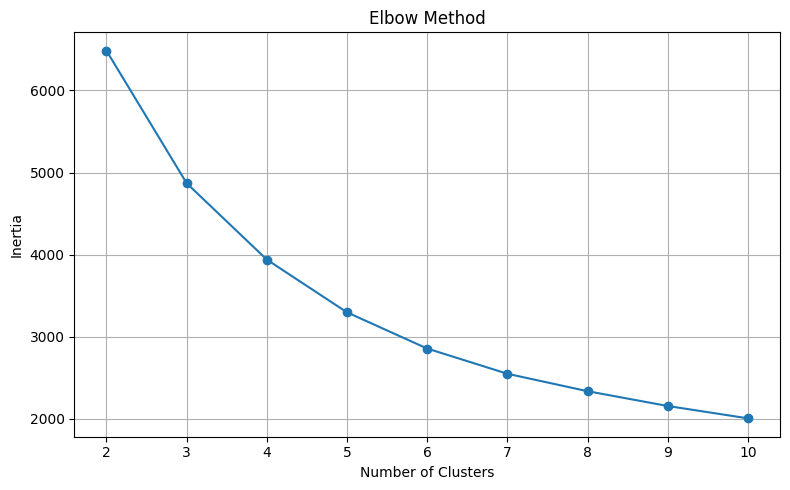

In [16]:
inertia_values = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(scaled_features)

    inertia_values.append(model.inertia_)

plt.figure(figsize=(8,5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker='o'
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid(True)

plt.tight_layout()
plt.savefig("charts/elbow_method.png", dpi=300)
plt.show()

K = 2, Silhouette Score = 0.4328
K = 3, Silhouette Score = 0.3365
K = 4, Silhouette Score = 0.3375
K = 5, Silhouette Score = 0.3162
K = 6, Silhouette Score = 0.3124
K = 7, Silhouette Score = 0.3092
K = 8, Silhouette Score = 0.3033


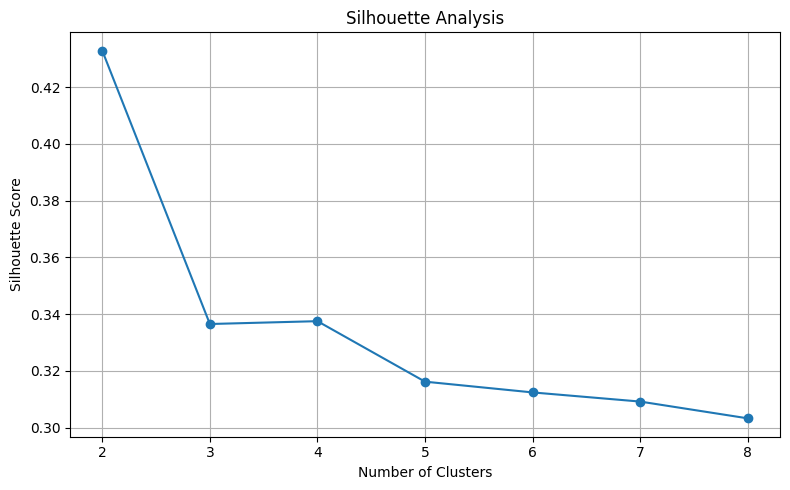

In [17]:
silhouette_scores = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_features)

    score = silhouette_score(
        scaled_features,
        labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

plt.figure(figsize=(8,5))

plt.plot(
    range(2, 9),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)

plt.tight_layout()
plt.savefig("charts/silhouette_analysis.png", dpi=300)
plt.show()

In [18]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(scaled_features)

print("K-Means Model Training Completed!")

print("\nCluster Distribution:")

print(rfm['Cluster'].value_counts().sort_index())

K-Means Model Training Completed!

Cluster Distribution:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [19]:
final_silhouette = silhouette_score(
    scaled_features,
    rfm['Cluster']
)

print("Final Silhouette Score:",
      round(final_silhouette, 4))

Final Silhouette Score: 0.3375


In [20]:
joblib.dump(
    {
        'model': kmeans,
        'scaler': scaler
    },
    "models/kmeans_customer_segmentation.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [21]:
cluster_profile = rfm.groupby('Cluster').agg(
    Recency=('Recency', 'median'),
    Frequency=('Frequency', 'median'),
    Monetary=('Monetary', 'median'),
    CustomerCount=('CustomerID', 'count')
)

# Calculate a relative customer value score
cluster_profile['ValueScore'] = (
    cluster_profile['Frequency'].rank(pct=True)
    +
    cluster_profile['Monetary'].rank(pct=True)
    +
    (-cluster_profile['Recency']).rank(pct=True)
)

# Rank clusters from highest to lowest score
ranked_clusters = cluster_profile.sort_values(
    'ValueScore',
    ascending=False
).index.tolist()

segment_names = [
    'Champions',
    'Regular Customers',
    'Occasional Buyers',
    'At-Risk Customers'
]

segment_mapping = dict(zip(
    ranked_clusters,
    segment_names
))

rfm['Segment'] = rfm['Cluster'].map(segment_mapping)

print("Customer Segmentation Completed!")

display(rfm.head())

Customer Segmentation Completed!


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,3,Regular Customers
1,12347.0,2,7,4310.00,0,Champions
2,12348.0,75,4,1797.24,3,Regular Customers
3,12349.0,19,1,1757.55,2,Occasional Buyers
4,12350.0,310,1,334.40,1,At-Risk Customers


In [22]:
rfm.to_csv(
    "outputs/customer_segmentation.csv",
    index=False
)

cluster_profile['Segment'] = (
    cluster_profile.index.map(segment_mapping)
)

cluster_profile.to_csv(
    "outputs/customer_segment_profiles.csv"
)

display(cluster_profile)

,Recency,Frequency,Monetary,CustomerCount,ValueScore,Segment
Cluster,,,,,,
0,8.0,10.0,3722.82,713,3.00,Champions
1,174.5,1.0,296.09,1622,0.75,At-Risk Customers
2,17.0,2.0,480.31,837,1.75,Occasional Buyers
3,57.0,4.0,1345.20,1166,2.00,Regular Customers


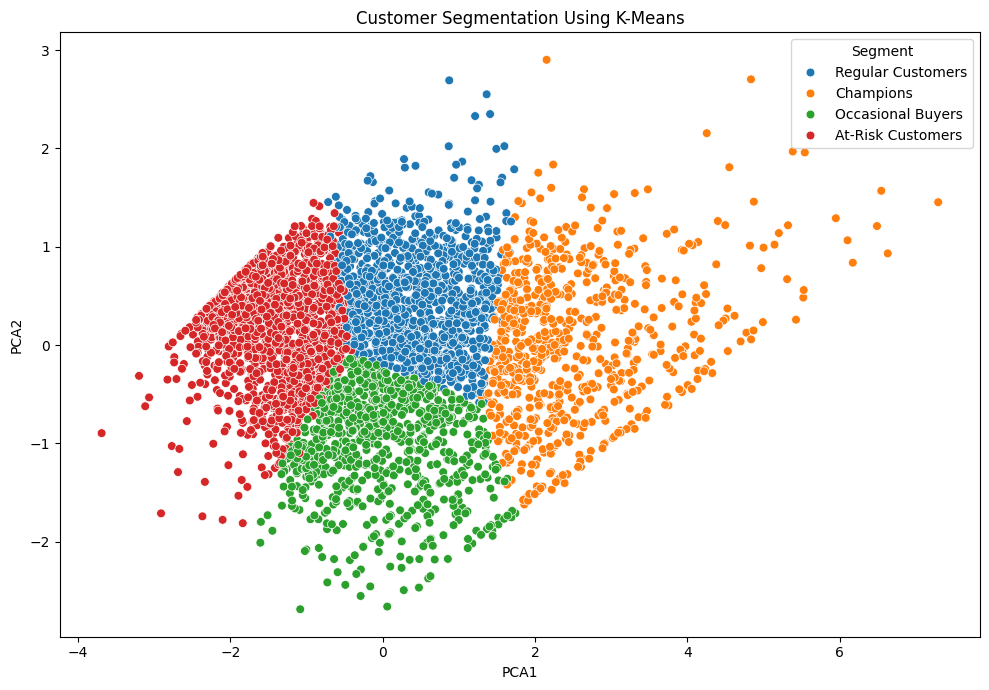

In [23]:
pca = PCA(n_components=2)

pca_features = pca.fit_transform(scaled_features)

plot_df = pd.DataFrame({
    'PCA1': pca_features[:, 0],
    'PCA2': pca_features[:, 1],
    'Segment': rfm['Segment']
})

plt.figure(figsize=(10,7))

sns.scatterplot(
    data=plot_df,
    x='PCA1',
    y='PCA2',
    hue='Segment',
    s=40
)

plt.title("Customer Segmentation Using K-Means")
plt.tight_layout()

plt.savefig(
    "charts/customer_clusters.png",
    dpi=300
)

plt.show()

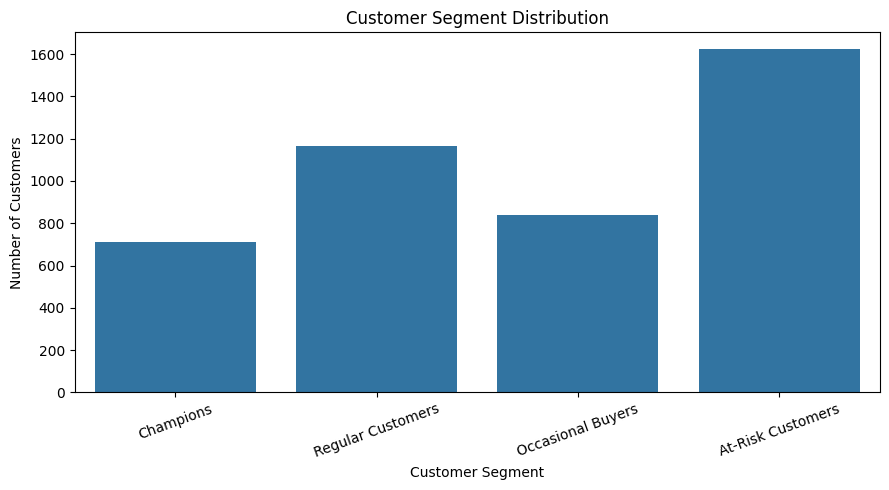

In [24]:
plt.figure(figsize=(9,5))

sns.countplot(
    data=rfm,
    x='Segment',
    order=segment_names
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)

plt.tight_layout()

plt.savefig(
    "charts/customer_segment_distribution.png",
    dpi=300
)

plt.show()

In [25]:
customer_item_matrix = df.pivot_table(
    index='CustomerID',
    columns='StockCode',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

print("Customer-Product Matrix Created!")

print("Matrix Shape:",
      customer_item_matrix.shape)

display(customer_item_matrix.head())

Customer-Product Matrix Created!
Matrix Shape: (4338, 3665)


StockCode,10002,10080,10120,10125,10133,10135,11001,15030,15034,15036,...,90214V,90214W,90214Y,90214Z,BANK CHARGES,C2,DOT,M,PADS,POST
CustomerID,,,,,,,,,,,,,,,,,,,,,
12346.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12347.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
12348.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
12349.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
12350.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [26]:
item_similarity = cosine_similarity(
    customer_item_matrix.T
)

item_similarity_df = pd.DataFrame(
    item_similarity,
    index=customer_item_matrix.columns,
    columns=customer_item_matrix.columns
)

print("Cosine Similarity Calculated!")

Cosine Similarity Calculated!


In [27]:
product_description = (
    df.groupby('StockCode')['Description']
    .agg(lambda x: x.mode().iloc[0]
         if not x.mode().empty else "Unknown")
)

display(product_description.head())

,Description
StockCode,
10002,INFLATABLE POLITICAL GLOBE
10080,GROOVY CACTUS INFLATABLE
10120,DOGGY RUBBER
10125,MINI FUNKY DESIGN TAPES
10133,COLOURING PENCILS BROWN TUBE


In [28]:
def recommend_products(customer_id, n=5):

    if customer_id not in customer_item_matrix.index:
        return pd.DataFrame(
            columns=['StockCode', 'Product', 'Similarity']
        )

    customer_purchases = customer_item_matrix.loc[
        customer_id
    ]

    purchased_products = customer_purchases[
        customer_purchases > 0
    ].index

    if len(purchased_products) == 0:
        return pd.DataFrame(
            columns=['StockCode', 'Product', 'Similarity']
        )

    # Calculate average similarity with purchased products
    scores = item_similarity_df[
        list(purchased_products)
    ].mean(axis=1)

    # Remove products already purchased
    scores = scores.drop(
        labels=purchased_products,
        errors='ignore'
    )

    # Select top recommendations
    top_products = scores.sort_values(
        ascending=False
    ).head(n)

    recommendations = pd.DataFrame({
        'StockCode': top_products.index,
        'Similarity': top_products.values
    })

    recommendations['Product'] = (
        recommendations['StockCode']
        .map(product_description)
    )

    return recommendations[
        ['StockCode', 'Product', 'Similarity']
    ]

In [29]:
sample_customer = customer_item_matrix.index[0]

print("Customer ID:", sample_customer)

recommendations = recommend_products(
    sample_customer,
    n=5
)

display(recommendations)

Customer ID: 12346.0


,StockCode,Product,Similarity
0,23165,LARGE CERAMIC TOP STORAGE JAR,0.008958
1,22652,TRAVEL SEWING KIT,0.007584
2,22985,WRAP BILLBOARD FONTS DESIGN,0.007535
3,21984,PACK OF 12 PINK PAISLEY TISSUES,0.007298
4,21980,PACK OF 12 RED RETROSPOT TISSUES,0.007018


In [30]:
all_recommendations = []

for customer_id in customer_item_matrix.index[:100]:

    customer_recommendations = recommend_products(
        customer_id,
        n=5
    )

    if not customer_recommendations.empty:

        customer_recommendations['CustomerID'] = (
            customer_id
        )

        all_recommendations.append(
            customer_recommendations
        )

if all_recommendations:

    recommendations_df = pd.concat(
        all_recommendations,
        ignore_index=True
    )

else:

    recommendations_df = pd.DataFrame(
        columns=[
            'CustomerID',
            'StockCode',
            'Product',
            'Similarity'
        ]
    )

display(recommendations_df.head(10))

,StockCode,Product,Similarity,CustomerID
0,23165,LARGE CERAMIC TOP STORAGE JAR,0.008958,12346.0
1,22652,TRAVEL SEWING KIT,0.007584,12346.0
2,22985,WRAP BILLBOARD FONTS DESIGN,0.007535,12346.0
3,21984,PACK OF 12 PINK PAISLEY TISSUES,0.007298,12346.0
4,21980,PACK OF 12 RED RETROSPOT TISSUES,0.007018,12346.0
5,22907,PACK OF 20 NAPKINS PANTRY DESIGN,0.195391,12347.0
6,23110,PARISIENNE KEY CABINET,0.194527,12347.0
7,22966,GINGERBREAD MAN COOKIE CUTTER,0.186147,12347.0
8,22505,MEMO BOARD COTTAGE DESIGN,0.185347,12347.0
9,22557,PLASTERS IN TIN VINTAGE PAISLEY,0.184179,12347.0


In [31]:
recommendations_df.to_csv(
    "outputs/product_recommendations.csv",
    index=False
)

print("Product recommendations saved!")

Product recommendations saved!


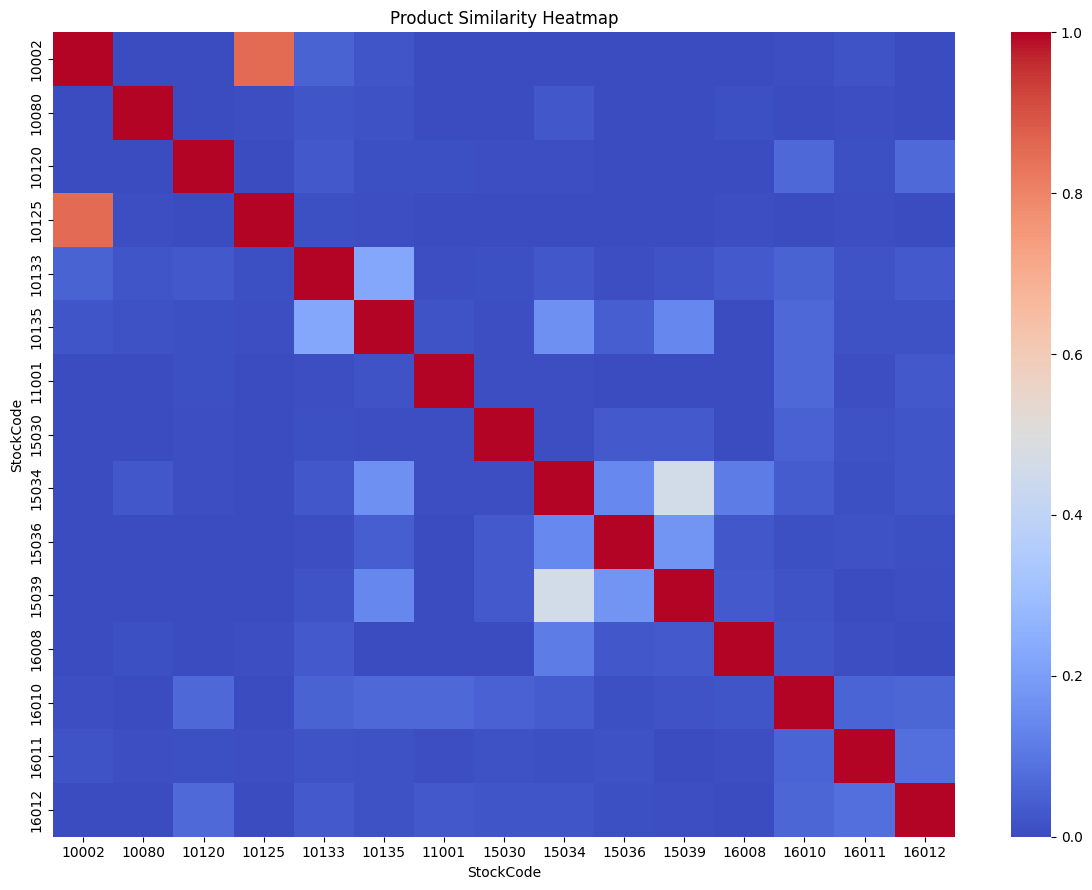

In [32]:
sample_products = item_similarity_df.index[:15]

plt.figure(figsize=(12,9))

sns.heatmap(
    item_similarity_df.loc[
        sample_products,
        sample_products
    ],
    cmap='coolwarm',
    annot=False
)

plt.title("Product Similarity Heatmap")

plt.tight_layout()

plt.savefig(
    "charts/product_similarity_heatmap.png",
    dpi=300
)

plt.show()

In [33]:
business_strategy = {
    'Champions':
        'Provide loyalty rewards, exclusive offers '
        'and early access to new products.',

    'Regular Customers':
        'Encourage repeat purchases through loyalty '
        'programs and personalized discounts.',

    'Occasional Buyers':
        'Offer targeted discounts and product bundles '
        'to increase purchase frequency.',

    'At-Risk Customers':
        'Use re-engagement campaigns, special offers '
        'and personalized emails.'
}

business_recommendations = pd.DataFrame({
    'Segment': segment_names,
    'Business_Recommendation': [
        business_strategy[name]
        for name in segment_names
    ]
})

display(business_recommendations)

,Segment,Business_Recommendation
0,Champions,"Provide loyalty rewards, exclusive offers and ..."
1,Regular Customers,Encourage repeat purchases through loyalty pro...
2,Occasional Buyers,Offer targeted discounts and product bundles t...
3,At-Risk Customers,"Use re-engagement campaigns, special offers an..."


In [34]:
business_recommendations.to_csv(
    "outputs/business_recommendations.csv",
    index=False
)

print("Business recommendations saved!")

Business recommendations saved!


In [35]:
print("=" * 50)
print("PROJECT SUMMARY")
print("=" * 50)

print("Total Transactions:", len(df))

print("Total Customers:", rfm['CustomerID'].nunique())

print("Total Products:", df['StockCode'].nunique())

print("Number of Clusters:", rfm['Cluster'].nunique())

print("Silhouette Score:",
      round(final_silhouette, 4))

print("\nCustomer Segment Counts:")

print(rfm['Segment'].value_counts())

print("\nProduct Recommendations Generated:",
      len(recommendations_df))

print("\nProject Completed Successfully!")

PROJECT SUMMARY
Total Transactions: 392692
Total Customers: 4338
Total Products: 3665
Number of Clusters: 4
Silhouette Score: 0.3375

Customer Segment Counts:
Segment
At-Risk Customers    1622
Regular Customers    1166
Occasional Buyers     837
Champions             713
Name: count, dtype: int64

Product Recommendations Generated: 500

Project Completed Successfully!


In [36]:
evaluation_summary = pd.DataFrame({
    'Metric': [
        'Total Transactions',
        'Total Customers',
        'Total Products',
        'Number of Clusters',
        'Silhouette Score',
        'Recommendations Generated'
    ],

    'Value': [
        len(df),
        rfm['CustomerID'].nunique(),
        df['StockCode'].nunique(),
        rfm['Cluster'].nunique(),
        round(final_silhouette, 4),
        len(recommendations_df)
    ]
})

evaluation_summary.to_csv(
    "outputs/evaluation_summary.csv",
    index=False
)

display(evaluation_summary)

,Metric,Value
0,Total Transactions,392692.0000
1,Total Customers,4338.0000
2,Total Products,3665.0000
3,Number of Clusters,4.0000
4,Silhouette Score,0.3375
5,Recommendations Generated,500.0000


In [37]:
os.makedirs("Ecommerce_Customer_Segmentation", exist_ok=True)

project_folder = "Ecommerce_Customer_Segmentation"

for folder in [
    "dataset",
    "outputs",
    "charts",
    "models",
    "screenshots"
]:

    os.makedirs(
        os.path.join(project_folder, folder),
        exist_ok=True
    )

In [38]:
import shutil

# Copy dataset
shutil.copy(
    "dataset/Online Retail.xlsx",
    f"{project_folder}/dataset/Online Retail.xlsx"
)

# Copy outputs
shutil.copytree(
    "outputs",
    f"{project_folder}/outputs",
    dirs_exist_ok=True
)

# Copy charts
shutil.copytree(
    "charts",
    f"{project_folder}/charts",
    dirs_exist_ok=True
)

# Copy model
shutil.copytree(
    "models",
    f"{project_folder}/models",
    dirs_exist_ok=True
)

print("Project files organized successfully!")

Project files organized successfully!


In [39]:
shutil.make_archive(
    "Ecommerce_Customer_Segmentation",
    "zip",
    project_folder
)

files.download(
    "Ecommerce_Customer_Segmentation.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>